# Milestone 2: student-directed pressure-forecasting analysis

Andres Arango Martinez · DS675. The student defined the engineering focus, local scope, analysis questions and requested figures. AI assisted methodological development, generated code and execution. This notebook presents the completed descriptive groundwork for the proposed learning experiments. See [student contributions](../docs/student_contributions.md).

## 1. Official data and environment

Run `python reproduce.py --download` first, or place the eleven official files in `data/raw/`. Published MD5s are verified before analysis. The annual files support table-structure checks; EDA, correlations and persistence use January–September 2018.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src').is_dir()
sys.path.insert(0, str(ROOT))
from src import analysis, figures, screening
from src.data import ensure_data
from IPython.display import display, Image
inputs = ensure_data(ROOT / 'data/raw')
print(f'{len(inputs)} official source files verified')

Verified 2018_SCADA_Pressures.csv


Verified 2018_SCADA_Flows.csv


Verified 2018_SCADA_Levels.csv


Verified 2018_SCADA_Demands.csv


Verified 2019_SCADA_Pressures.csv


...

Verified 2019_SCADA_Demands.csv


Verified L-TOWN.inp


Verified dataset_configuration.yaml


Verified README.txt


11 official source files verified


## 2. Check all eight annual tables and select six signals

The four measurement tables in each year are checked for unique, aligned, complete five-minute timestamps and expected shapes. The student-selected 2018 signals are n1/n4/n31 pressure, tank level, pump flow and target-junction consumption. Recorded units are retained.

In [2]:
x, structure = analysis.read_and_check_tables(ROOT / 'data/raw')
display(x.head())
print({'rows': len(x), 'signals': list(x.columns)})

Checked 2018_SCADA_Pressures.csv: 105,120 rows, 33 channels


Checked 2018_SCADA_Flows.csv: 105,120 rows, 3 channels


Checked 2018_SCADA_Levels.csv: 105,120 rows, 1 channels


Checked 2018_SCADA_Demands.csv: 105,120 rows, 82 channels


Checked 2019_SCADA_Pressures.csv: 105,120 rows, 33 channels


Checked 2019_SCADA_Flows.csv: 105,120 rows, 3 channels


Checked 2019_SCADA_Levels.csv: 105,120 rows, 1 channels


Checked 2019_SCADA_Demands.csv: 105,120 rows, 82 channels


,n1,n4,n31,T1,PUMP_1,AMR_n1
Timestamp,,,,,,
2018-01-01 00:00:00,28.92,33.87,37.13,3.50,44.04,40.83
2018-01-01 00:05:00,28.94,33.89,37.16,3.51,44.06,40.20
2018-01-01 00:10:00,28.96,33.91,37.18,3.53,44.06,38.06
2018-01-01 00:15:00,28.98,33.93,37.19,3.54,44.07,37.24
2018-01-01 00:20:00,28.98,33.93,37.19,3.56,44.03,45.38


{'rows': 78624, 'signals': ['n1', 'n4', 'n31', 'T1', 'PUMP_1', 'AMR_n1']}


## 3. Align the future label and calculate descriptive evidence

Crop the period first, then shift n1 by three rows. Eligible pairs keep their future label within September. Persistence repeats current n1; its error is future n1 minus current n1. The 78,621 pairs support descriptive analysis. The proposed learning matrix will add 55-minute histories.

In [3]:
stats, corr, pairs = analysis.describe(x)
print(json.dumps(stats, indent=2))
display(pairs.head())
display(corr.round(4))
expected = json.loads((ROOT / 'evidence/reported_values.json').read_text())
for metric in ['persistence_MAE_m', 'persistence_RMSE_m']:
    assert abs(stats[metric] - expected[metric]) < 1e-12
assert len(pairs) == 78621
print('Reported descriptive values agree')

{
  "period_start": "2018-01-01",
  "period_end": "2018-09-30",
  "days": 273,
  "rows": 78624,
  "forecast_pairs": 78621,
  "lead_minutes": 15,
  "n1_range_m": [
    25.67,
    29.36
  ],
  "persistence_MAE_m": 0.05177624298851451,
  "persistence_RMSE_m": 0.06849175638676988,
  "correlation_with_future_n1": {
    "n1": 0.9923104288422745,
    "n4": 0.9751781370318049,
    "n31": 0.9709194921762693,
    "T1": 0.9230382756150715,
    "PUMP_1": -0.036721113537103056,
    "AMR_n1": -0.15737833061358575
  },
  "signals": [
    "n1",
    "n4",
    "n31",
    "T1",
    "PUMP_1",
    "AMR_n1"
  ],
  "target": "n1_plus15",
  "interpretation": "Descriptive Jan-Sep 2018 results; not a final 2019 test score.",
  "learned_models_fitted": false
}


,n1,n4,n31,T1,PUMP_1,AMR_n1,n1_plus15
Timestamp,,,,,,,
2018-01-01 00:00:00,28.92,33.87,37.13,3.50,44.04,40.83,28.98
2018-01-01 00:05:00,28.94,33.89,37.16,3.51,44.06,40.20,28.98
2018-01-01 00:10:00,28.96,33.91,37.18,3.53,44.06,38.06,29.01
2018-01-01 00:15:00,28.98,33.93,37.19,3.54,44.07,37.24,29.03
2018-01-01 00:20:00,28.98,33.93,37.19,3.56,44.03,45.38,29.03


,n1,n4,n31,T1,PUMP_1,AMR_n1,n1_plus15
n1,1.0000,0.9819,0.9824,0.9383,-0.0973,-0.1351,0.9923
n4,0.9819,1.0000,0.9845,0.9408,-0.0961,-0.0353,0.9752
n31,0.9824,0.9845,1.0000,0.9789,-0.1582,0.0187,0.9709
T1,0.9383,0.9408,0.9789,1.0000,-0.2028,0.0981,0.9230
PUMP_1,-0.0973,-0.0961,-0.1582,-0.2028,1.0000,-0.3429,-0.0367
AMR_n1,-0.1351,-0.0353,0.0187,0.0981,-0.3429,1.0000,-0.1574
n1_plus15,0.9923,0.9752,0.9709,0.9230,-0.0367,-0.1574,1.0000


Reported descriptive values agree


## 4. Nominal supply boundary and pipe paths

The released nominal model defines the supply boundary. Initially open pipes form undirected components, with pumps and PRVs defining the boundaries. Dijkstra sums nominal pipe lengths to the three measured nodes, providing their spatial ranking. Figure 1 interprets the functional supply route.

In [4]:
topology = analysis.nominal_topology(ROOT / 'data/raw')
print(json.dumps({k: topology[k] for k in ['network_counts','sectors','T1_to_measured_pressure_nodes','feature_filter_counts']}, indent=2))

{
  "network_counts": {
    "junctions": 782,
    "reservoirs": 2,
    "tanks": 1,
    "pipes": 905,
    "pumps": 1,
    "valves": 3
  },
  "sectors": {
    "A": {
      "junctions": 657,
      "pressure_sensors": [
        "n54",
        "n105",
        "n114",
        "n163",
        "n188",
        "n229",
        "n288",
        "n296",
        "n332",
        "n342",
        "n410",
        "n415",
        "n429",
        "n458",
        "n469",
        "n495",
        "n506",
        "n516",
        "n519",
        "n549",
        "n613",
        "n636",
        "n644",
        "n679",
        "n722",
        "n726",
        "n740",
        "n752",
        "n769"
      ],
      "pressure_sensor_count": 29,
      "AMR_count": 0
    },
    "B": {
      "junctions": 31,
      "pressure_sensors": [
        "n215"
      ],
      "pressure_sensor_count": 1,
      "AMR_count": 0
    },
    "C": {
      "junctions": 92,
      "pressure_sensors": [
        "n1",
        "n4",
        "n31

## 5. Recount the documented literature

Join 47 source records to their 35 related-work groups. Five primary objectives determine the bars; gold identifies the six selected groups. This verifies inventory membership and count consistency. The notes distinguish focused relevance screening and closer review, with Ahmed as a separate feedback supplement.

In [5]:
counts = screening.recount()
print(json.dumps(counts, indent=2))
assert counts['source_records'] == 47 and counts['groups'] == 35
assert [row['groups'] for row in counts['categories']] == [27, 3, 2, 2, 1]

{
  "source_records": 47,
  "groups": 35,
  "selected_groups": 6,
  "categories": [
    {
      "category": "leak",
      "label": "Leak detection / localization",
      "groups": 27,
      "percent": 77.14285714285714,
      "selected": 3,
      "group_ids": [
        "lila",
        "under-pressure",
        "ciacua",
        "dhi-sg",
        "wu-bsy",
        "tsinghua",
        "dandw",
        "chebnet",
        "liquor",
        "gsi-dl",
        "gan",
        "topological",
        "li-chen",
        "aignn",
        "autoencoders",
        "unife",
        "artesia",
        "cubalytics",
        "tongji",
        "dhi-china",
        "infrasense",
        "ku",
        "iri",
        "zhiyun",
        "cheng",
        "fluing",
        "aquasentinel"
      ]
    },
    {
      "category": "state",
      "label": "Current-state estimation",
      "groups": 3,
      "percent": 8.571428571428571,
      "selected": 1,
      "group_ids": [
        "gatres",
        "dual-ukf",
  

## 6. Regenerate all four figures

Use the established serif/navy/teal/gold style and portable fonts. The preserved submitted images retain the original rendering; regenerated figures present the same quantities and layout.

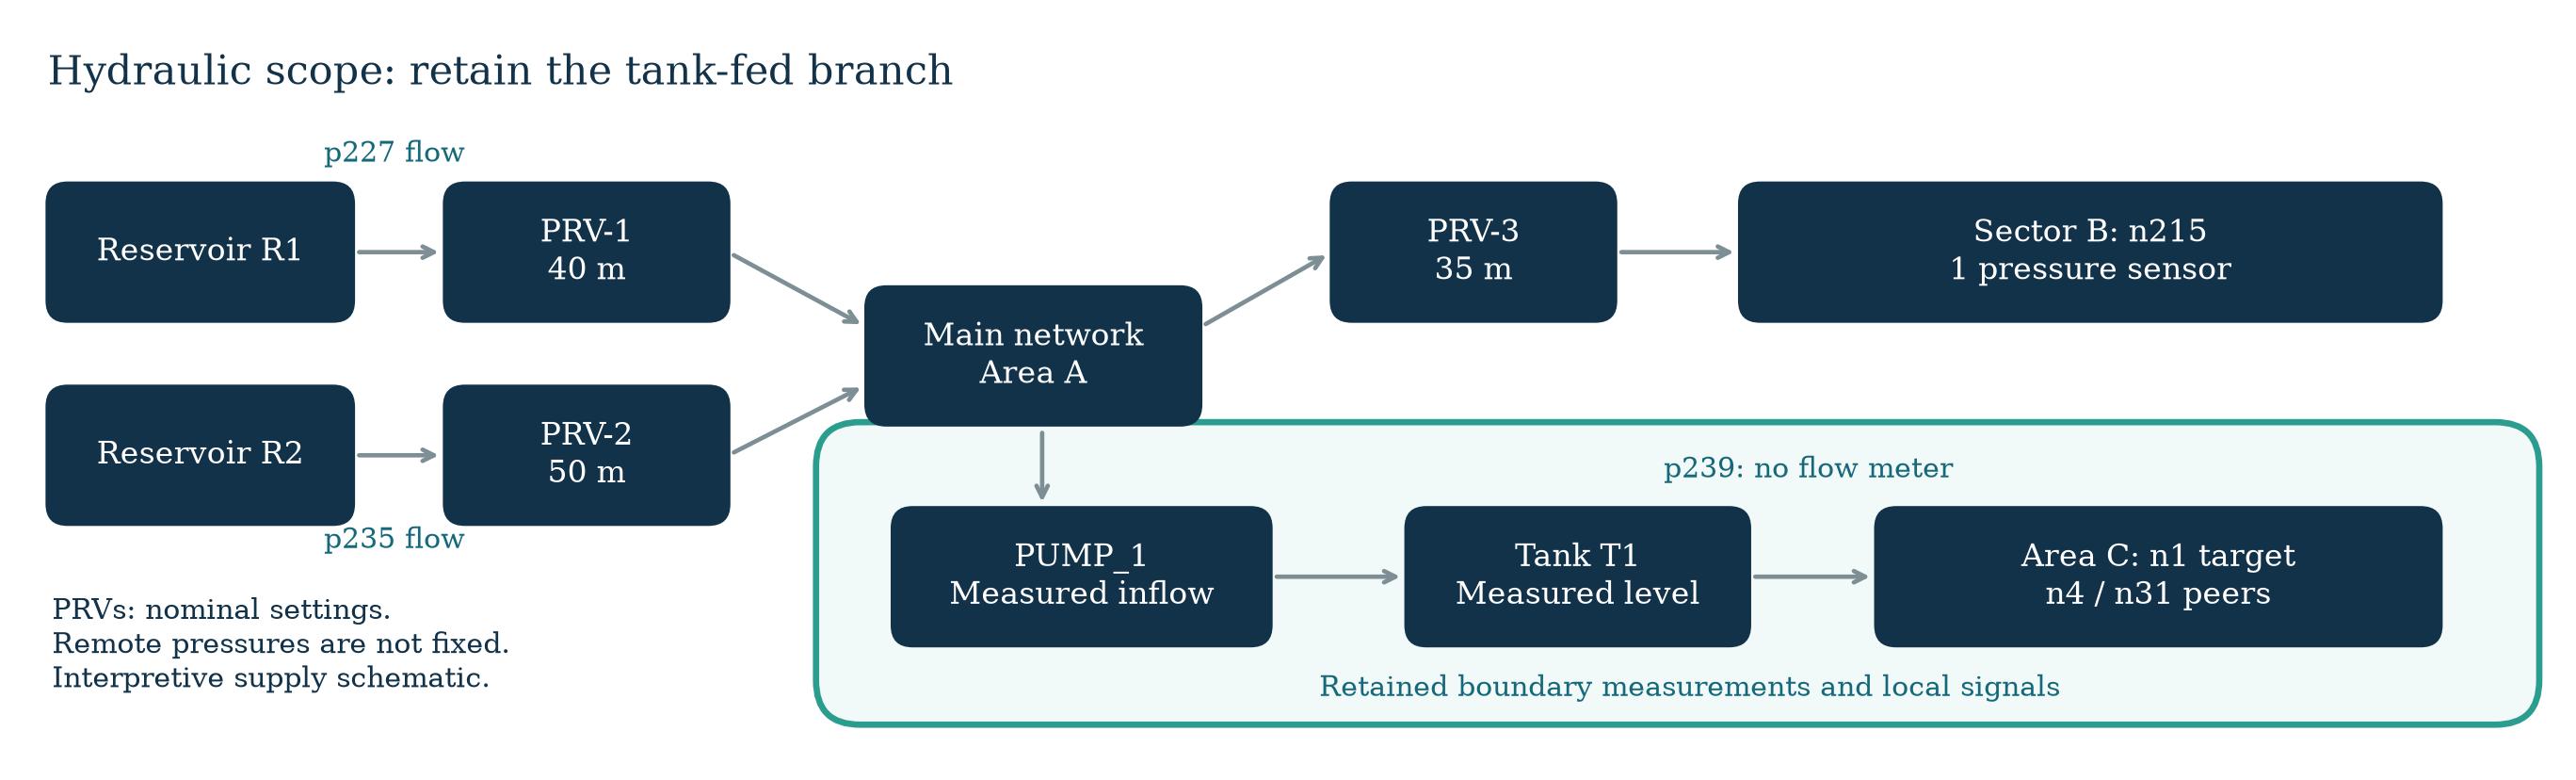

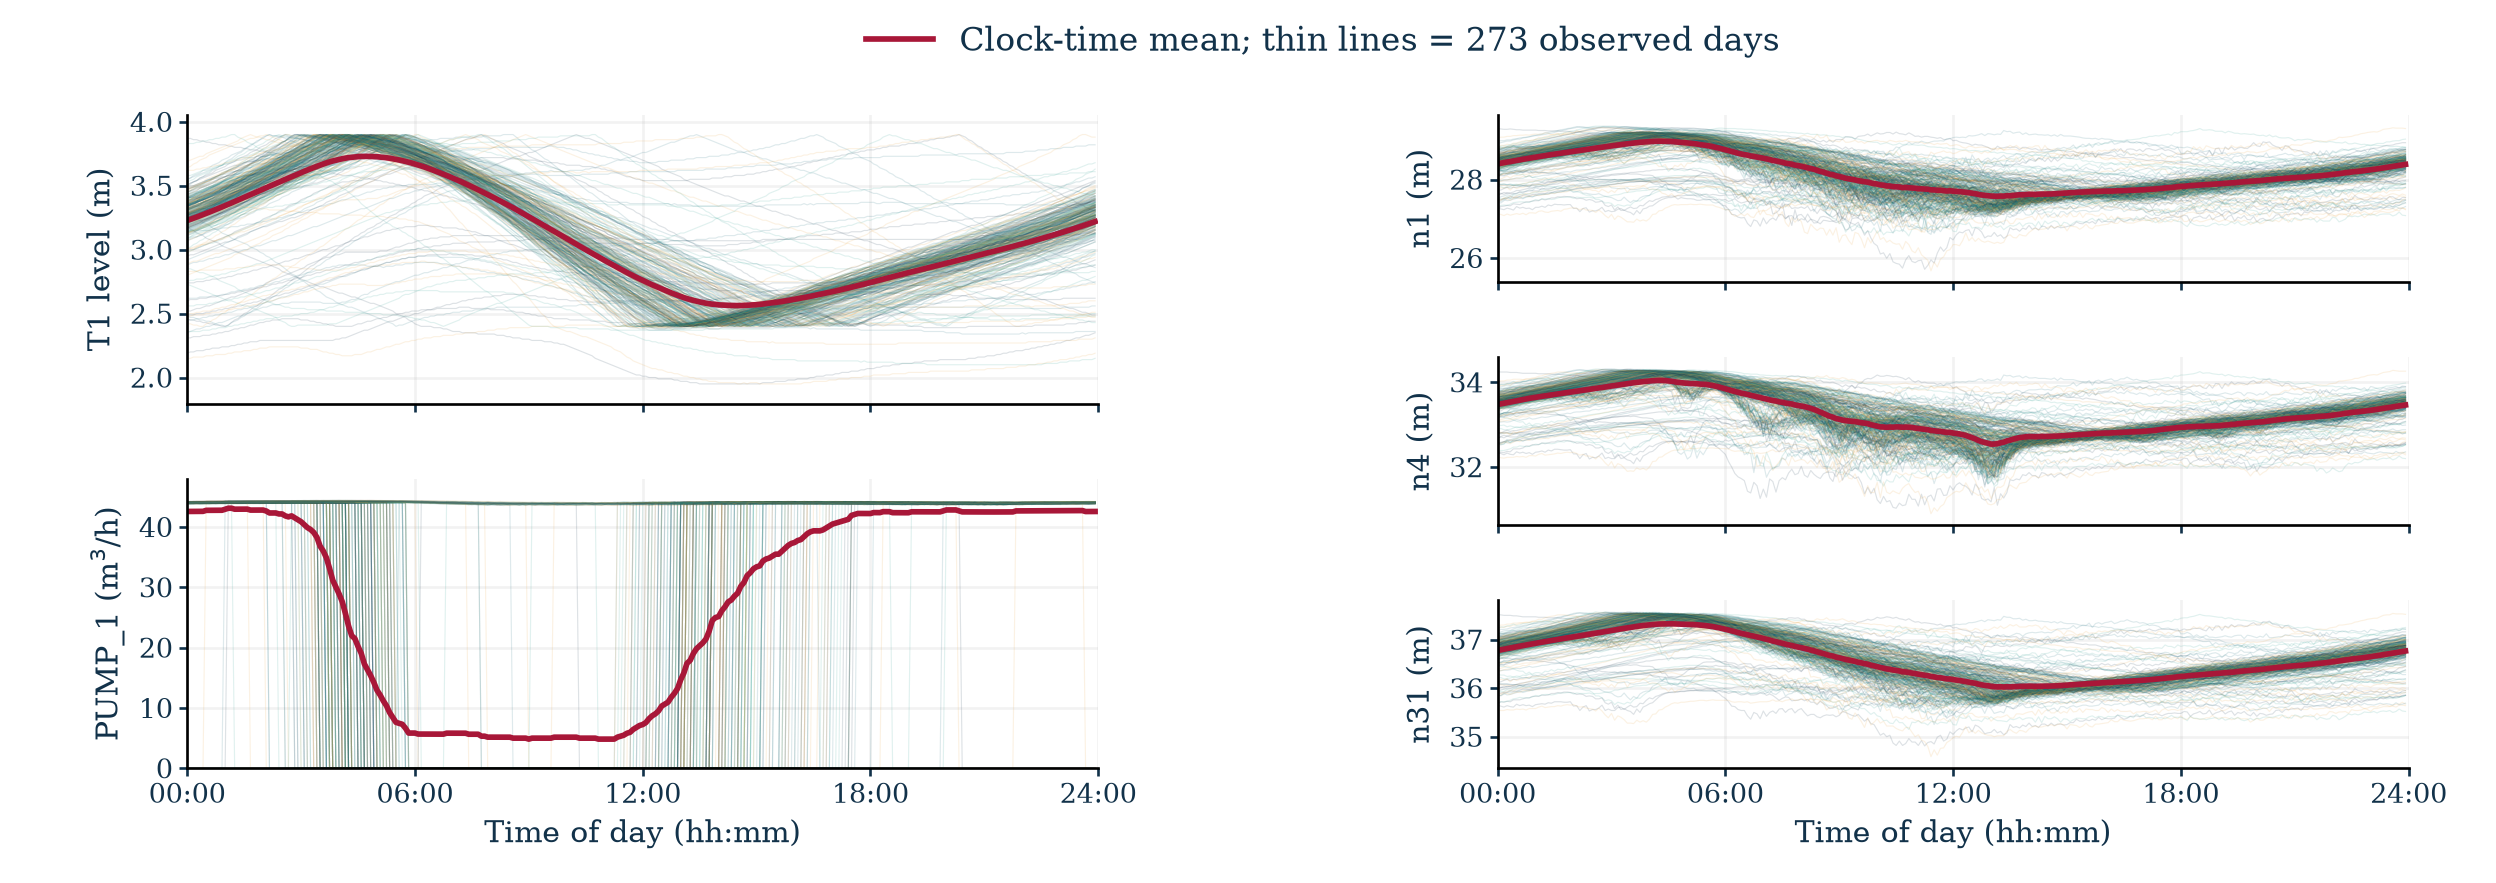

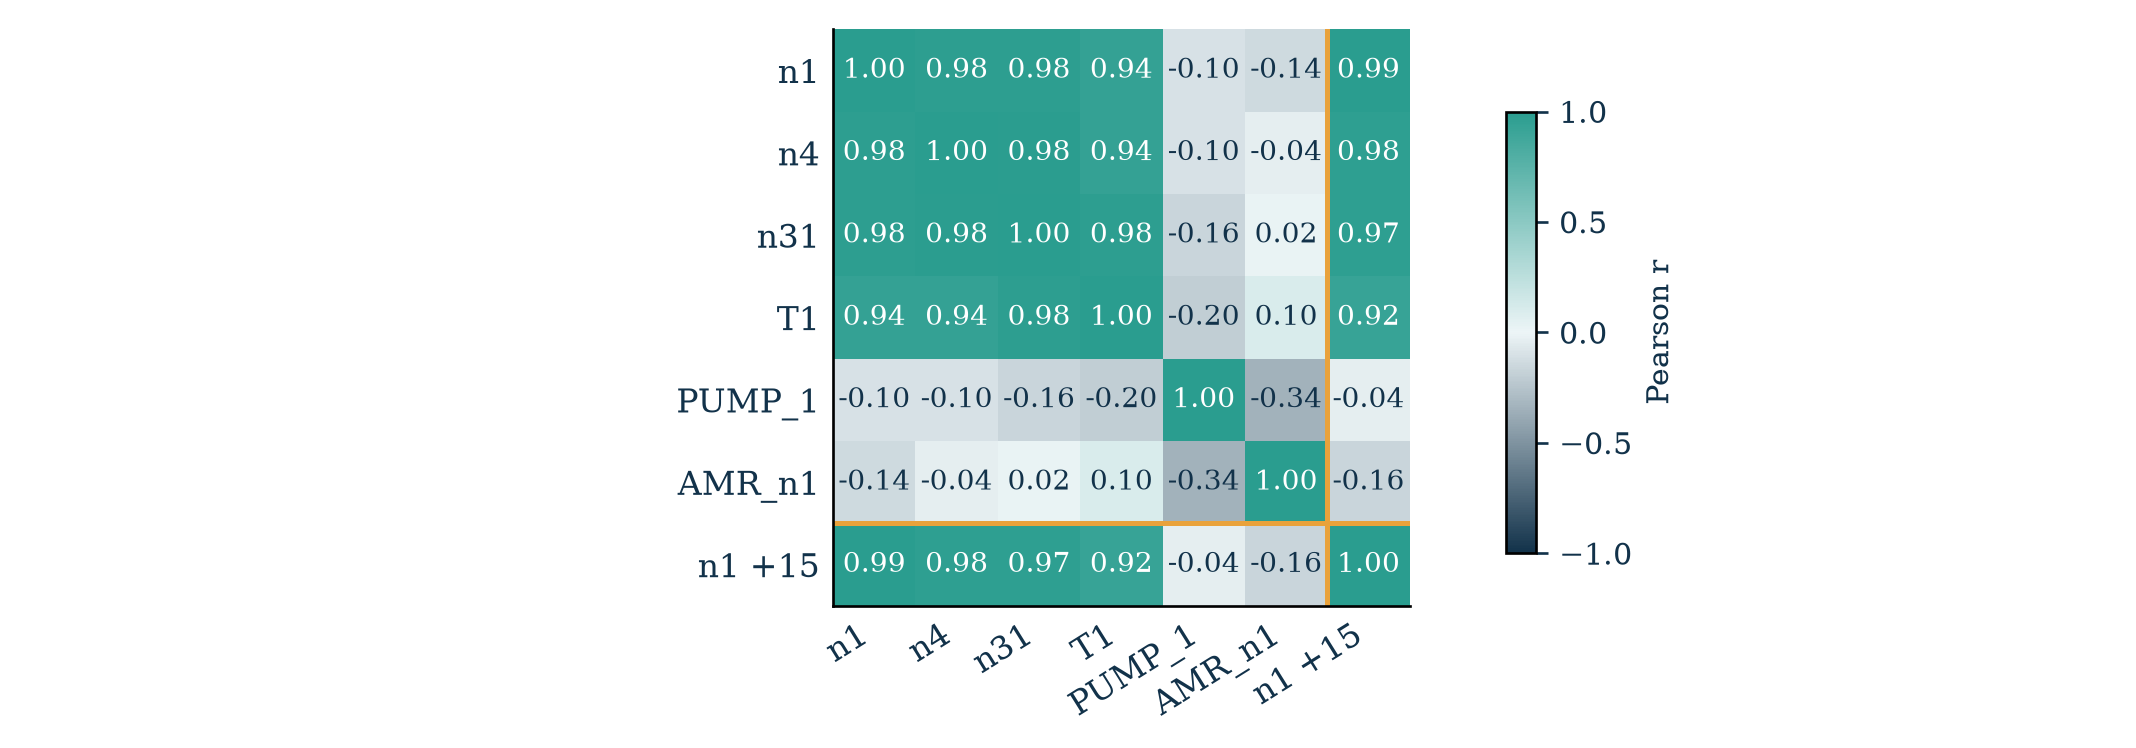

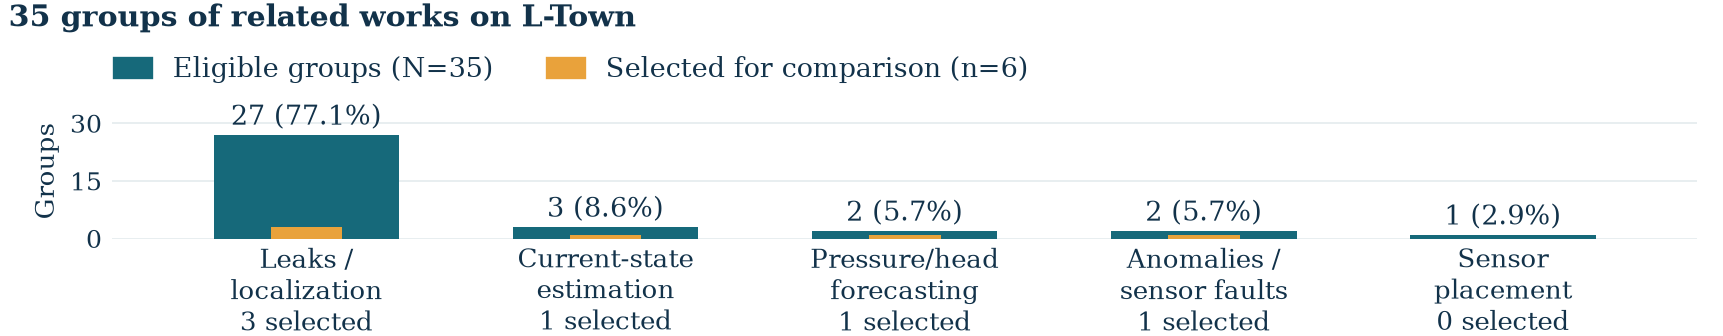

In [6]:
folder = ROOT / 'results/notebook/figures'
folder.mkdir(parents=True, exist_ok=True)
figures.supply_boundary(topology, folder)
figures.daily_profiles(x, folder)
figures.correlations(corr, folder)
figures.screening(counts, folder)
for name in ['figure1_supply_boundary', 'figure2_daily_profiles', 'figure3_correlations', 'figure4_historical_screening']:
    display(Image(filename=str(folder / (name + '.png')), width=950))

## 7. Research contribution and next stage

The student's local hydraulic reasoning and requested visual comparisons give a concrete foundation for the forecast study. Slowly changing pressure makes persistence a demanding reference. C1 will prepare the lagged data, C2 will compare Gradient Boosting/persistence/Ridge/Random Forest, and C3 will measure the auxiliary set's joint value against n1 history with the same calendar variables. These planned experiments will evaluate the predictive value of the selected signals.

In [7]:
print({'descriptive_period': 'January–September 2018', 'models_trained': False, '2019_forecast_scores_computed': False})

{'descriptive_period': 'January–September 2018', 'models_trained': False, '2019_forecast_scores_computed': False}
